# [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jeanfrancois-lafreniere/sci1402-bank-customer-churn/blob/main/notebook_sci1402_bank_churn_analysis.ipynb)
# SCI 1402 – Projet en science des données
## Analyse prédictive du désabonnement client (*Bank Customer Churn*)

* **Auteur :** Jean-François Lafrenière
* **Établissement :** Université TÉLUQ (Certificat en science des données)
* **Tutrice :** Fatima Bensalma
* **Source des données :** Kaggle (*Bank Customer Churn*)
* **Dépôt GitHub :** [prediction-attrition-bancaire](https://github.com/jeanfrancois-lafreniere/prediction-attrition-bancaire)

# **Installation bibliothèque**

In [1]:
!pip install -q pingouin "pandas==2.2.3"

In [2]:
# ==========================================
# 1. IMPORTATION DES BIBLIOTHÈQUES
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

url_raw = "https://raw.githubusercontent.com/jeanfrancois-lafreniere/prediction-attrition-bancaire/main/data/Customer-Churn-Records.csv"

# Chargement des données
df = pd.read_csv(url_raw)

# Affichage des 5 premières lignes
df.head()






,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


**Unification et inspection des variables catégoriques**

In [3]:
# 1. Dimensions du jeu de données (nombre de lignes et colonnes)
print(f"Dimensions du dataset : {df.shape[0]} lignes, {df.shape[1]} colonnes\n")

# 2. Informations sur les types de données et valeurs non nulles
print("--- Informations générales ---")
df.info()

# 3. Vérification des valeurs manquantes (Null / NaN)
print("\n--- Valeurs manquantes par colonne ---")
print(df.isnull().sum())

# 4. Vérification des doublons
print(f"\nNombre de lignes doublons : {df.duplicated().sum()}")

Dimensions du dataset : 10000 lignes, 18 colonnes

--- Informations générales ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            1

In [4]:
# ==========================================
# Inspection des catégories (Unification des intitulés)
# ==========================================
for col in ['Geography', 'Gender', 'Card Type']:
    print(f"--- Valeurs uniques pour {col} ---")
    print(df[col].value_counts(), "\n")

--- Valeurs uniques pour Geography ---
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64 

--- Valeurs uniques pour Gender ---
Gender
Male      5457
Female    4543
Name: count, dtype: int64 

--- Valeurs uniques pour Card Type ---
Card Type
DIAMOND     2507
GOLD        2502
SILVER      2496
PLATINUM    2495
Name: count, dtype: int64 



In [5]:
# 1. Distribution de la variable cible (Exited)
churn_counts = df['Exited'].value_counts()
churn_pct = df['Exited'].value_counts(normalize=True) * 100

print("--- Répartition de la clientèle (0 = Restés, 1 = Partis) ---")
for val in [0, 1]:
    label = "Restés (0)" if val == 0 else "Partis / Churn (1)"
    print(f"{label} : {churn_counts[val]} clients ({churn_pct[val]:.2f}%)")

# 2. Aperçu des statistiques descriptives
print("\n--- Statistiques descriptives ---")
# Forcer l'affichage avec 2 décimales au lieu de la notation scientifique
pd.set_option('display.float_format', lambda x: '%.2f' % x)
display(df.describe().T)

--- Répartition de la clientèle (0 = Restés, 1 = Partis) ---
Restés (0) : 7962 clients (79.62%)
Partis / Churn (1) : 2038 clients (20.38%)

--- Statistiques descriptives ---


,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.00,5000.50,2886.90,1.00,2500.75,5000.50,7500.25,10000.00
CustomerId,10000.00,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
CreditScore,10000.00,650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,10000.00,38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,10000.00,5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,10000.00,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
NumOfProducts,10000.00,1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,10000.00,0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,10000.00,0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,10000.00,100090.24,57510.49,11.58,51002.11,100193.91,149388.25,199992.48


In [6]:
# Distribution des plaintes
df['Complain'].value_counts(normalize=True) * 100

,proportion
Complain,
0,79.56
1,20.44


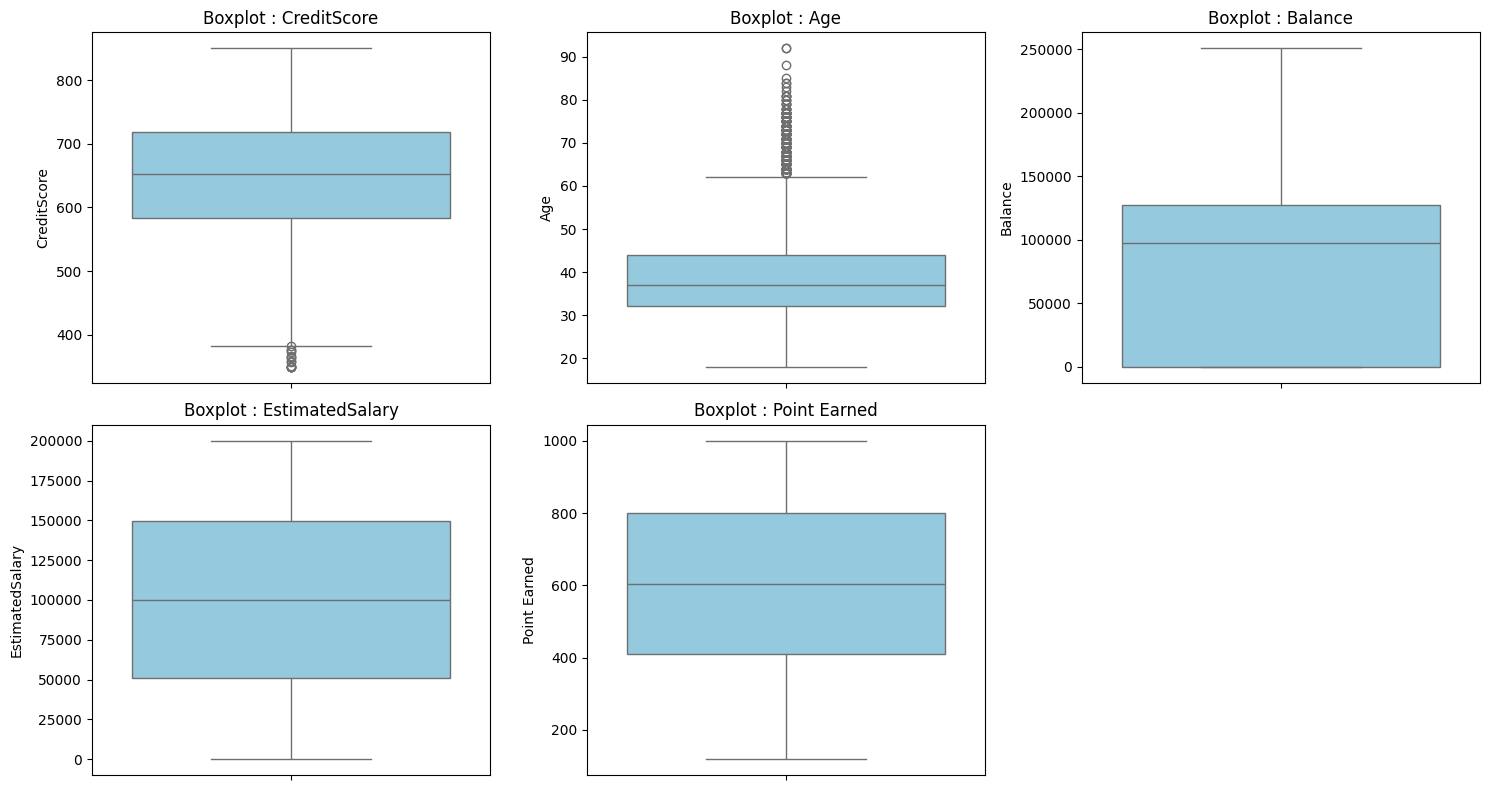

In [7]:
# Sélection des variables numériques continues
cols_numeriques = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary', 'Point Earned']

plt.figure(figsize=(15, 8))
for i, col in enumerate(cols_numeriques, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Boxplot : {col}')

plt.tight_layout()
plt.show()

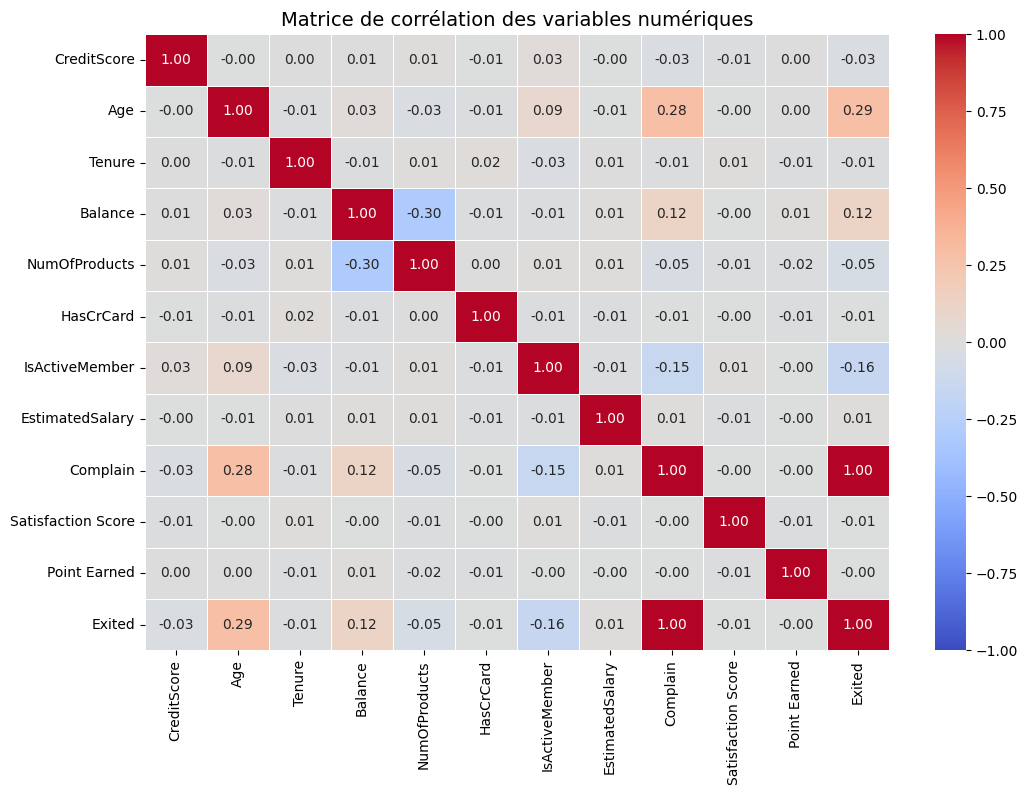

In [8]:
##### Calculer et visualiser la matrice de corrélation (identifier d'un seul coup d'œil quelles variables
###### ont la plus forte relation linéaire avec le départ du client (Exited))

# 1. Sélection des variables numériques utiles pour la corrélation
cols_corr = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
             'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
             'Complain', 'Satisfaction Score', 'Point Earned', 'Exited']

# 2. Calcul de la matrice de corrélation (Pearson)
corr_matrix = df[cols_corr].corr()

# 3. Affichage sous forme de carte thermique (Heatmap)
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matrice de corrélation des variables numériques", fontsize=14)
plt.show()

# **Test du Khi-Carré - Variables catégorielles vs Exited**

In [9]:
from scipy.stats import chi2_contingency

vars_categorielles = ['Geography', 'Gender', 'IsActiveMember', 'HasCrCard', 'NumOfProducts', 'Card Type']

print("=== RÉSULTATS DES TESTS DU KHI-DEUX (Variables Catégorielles vs Exited) ===\n")

for col in vars_categorielles:
    # 1. Tableau des effectifs bruts (utilisé pour le calcul du Khi-deux)
    tableau_contingence = pd.crosstab(df[col], df['Exited'])
    chi2, p_val, dof, expected = chi2_contingency(tableau_contingence)

    significatif = "OUI (Rejet de H0)" if p_val < 0.05 else "NON (H0 conservée)"
    print(f"Variable : {col:<18} | Chi2 = {chi2:>8.2f} | ddl = {dof} | p-value = {p_val:.4e} | Significatif : {significatif}")

    # 2. Affichage des pourcentages par ligne pour interpréter le sens du lien
    if p_val < 0.05:
        tableau_pct = (pd.crosstab(df[col], df['Exited'], normalize='index') * 100).round(2)
        tableau_pct.columns = ['Fidèle - 0 (%)', 'Churn - 1 (%)']
        display(tableau_pct)
        print("-" * 80)

=== RÉSULTATS DES TESTS DU KHI-DEUX (Variables Catégorielles vs Exited) ===

Variable : Geography          | Chi2 =   300.63 | ddl = 2 | p-value = 5.2457e-66 | Significatif : OUI (Rejet de H0)


,Fidèle - 0 (%),Churn - 1 (%)
Geography,,
France,83.83,16.17
Germany,67.56,32.44
Spain,83.33,16.67


--------------------------------------------------------------------------------
Variable : Gender             | Chi2 =   112.40 | ddl = 1 | p-value = 2.9254e-26 | Significatif : OUI (Rejet de H0)


,Fidèle - 0 (%),Churn - 1 (%)
Gender,,
Female,74.93,25.07
Male,83.53,16.47


--------------------------------------------------------------------------------
Variable : IsActiveMember     | Chi2 =   243.69 | ddl = 1 | p-value = 6.1532e-55 | Significatif : OUI (Rejet de H0)


,Fidèle - 0 (%),Churn - 1 (%)
IsActiveMember,,
0,73.13,26.87
1,85.73,14.27


--------------------------------------------------------------------------------
Variable : HasCrCard          | Chi2 =     0.45 | ddl = 1 | p-value = 5.0262e-01 | Significatif : NON (H0 conservée)
Variable : NumOfProducts      | Chi2 =  1501.50 | ddl = 3 | p-value = 0.0000e+00 | Significatif : OUI (Rejet de H0)


,Fidèle - 0 (%),Churn - 1 (%)
NumOfProducts,,
1,72.29,27.71
2,92.40,7.60
3,17.29,82.71
4,0.00,100.00


--------------------------------------------------------------------------------
Variable : Card Type          | Chi2 =     5.05 | ddl = 3 | p-value = 1.6794e-01 | Significatif : NON (H0 conservée)


Les résultats de notre test Khi-carré démontre plusieurs interactions

# Test t de Welch - Compare moyenne des variables continu avec variable de sortie (Exited = 0 vs Exited = 1)

In [10]:
from scipy.stats import ttest_ind

vars_continues_test = ['Age', 'Balance', 'CreditScore', 'Tenure', 'EstimatedSalary', 'Satisfaction Score', 'Point Earned']

groupe_fidele = df[df['Exited'] == 0]
groupe_churn = df[df['Exited'] == 1]

resultats_welch = []

for col in vars_continues_test:
    t_stat, p_val = ttest_ind(groupe_fidele[col], groupe_churn[col], equal_var=False)

    resultats_welch.append({
        'Variable': col,
        'Moy. Fidèles (0)': round(groupe_fidele[col].mean(), 2),
        'ET Fidèles (0)': round(groupe_fidele[col].std(), 2),
        'Méd. Fidèles (0)': round(groupe_fidele[col].median(), 2),
        'Moy. Churn (1)': round(groupe_churn[col].mean(), 2),
        'ET Churn (1)': round(groupe_churn[col].std(), 2),
        'Méd. Churn (1)': round(groupe_churn[col].median(), 2),
        'Statistique t': round(t_stat, 2),
        'p-value': f"{p_val:.4e}",
        'Significatif (α=0,05)': "Oui" if p_val < 0.05 else "Non"
    })

df_welch = pd.DataFrame(resultats_welch)
print("=== RÉSULTATS DES TESTS T DE WELCH (Moyennes et dispersions : Fidèles vs Churn) ===")
display(df_welch)

=== RÉSULTATS DES TESTS T DE WELCH (Moyennes et dispersions : Fidèles vs Churn) ===


,Variable,Moy. Fidèles (0),ET Fidèles (0),Méd. Fidèles (0),Moy. Churn (1),ET Churn (1),Méd. Churn (1),Statistique t,p-value,"Significatif (α=0,05)"
0,Age,37.41,10.13,36.00,44.84,9.76,45.00,-30.42,4.3995e-179,Oui
1,Balance,72742.75,62851.58,92063.06,91109.48,58346.48,109344.23,-12.48,5.8176e-35,Oui
2,CreditScore,651.84,95.65,653.00,645.41,100.34,646.00,2.60,9.2849e-03,Oui
3,Tenure,5.03,2.88,5.00,4.93,2.94,5.00,1.35,1.7711e-01,Non
4,EstimatedSalary,99726.85,57399.96,99620.35,101509.91,57932.62,102489.33,-1.24,2.1428e-01,Non
5,Satisfaction Score,3.02,1.41,3.00,3.00,1.40,3.00,0.59,5.5730e-01,Non
6,Point Earned,607.04,226.09,603.00,604.45,225.32,610.50,0.46,6.4288e-01,Non


# **ANOVA**

In [11]:
import pingouin as pg

print("=== ANOVA DE WELCH ET TEST POST-HOC GAMES-HOWELL PAR PAYS ===\n")

for col in ['Balance', 'Age']:
    print(f"--- Variable analysée : {col} ---")

    # 1. Statistiques descriptives par pays (montre l'écart-type et la médiane de chaque marché)
    desc_pays = df.groupby('Geography')[col].agg(
        Effectif='count',
        Moyenne='mean',
        Ecart_Type='std',
        Mediane='median'
    ).round(2)
    display(desc_pays)

    # 2. ANOVA de Welch
    welch = pg.welch_anova(dv=col, between='Geography', data=df)
    display(welch)

    # 3. Test Post-Hoc de Games-Howell
    gh = pg.pairwise_gameshowell(dv=col, between='Geography', data=df)
    display(gh)
    print("-" * 80 + "\n")

=== ANOVA DE WELCH ET TEST POST-HOC GAMES-HOWELL PAR PAYS ===

--- Variable analysée : Balance ---


,Effectif,Moyenne,Ecart_Type,Mediane
Geography,,,,
France,5014,62092.64,64133.57,62153.50
Germany,2509,119730.12,27022.01,119703.10
Spain,2477,61818.15,64235.56,61710.44


,Source,ddof1,ddof2,F,p_unc,np2
0,Geography,2,5528.65,1981.82,0.00,0.16


,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,France,Germany,62092.64,119730.12,-57637.48,1054.21,-54.67,7351.45,0.00,-1.05
1,France,Spain,62092.64,61818.15,274.49,1576.75,0.17,4925.13,0.98,0.00
2,Germany,Spain,119730.12,61818.15,57911.97,1398.87,41.40,3316.78,0.00,1.18


--------------------------------------------------------------------------------

--- Variable analysée : Age ---


,Effectif,Moyenne,Ecart_Type,Mediane
Geography,,,,
France,5014,38.51,10.47,37.00
Germany,2509,39.77,10.52,38.00
Spain,2477,38.89,10.45,37.00


,Source,ddof1,ddof2,F,p_unc,np2
0,Geography,2,5310.48,12.04,0.00,0.00


,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,France,Germany,38.51,39.77,-1.26,0.26,-4.91,4996.39,0.00,-0.12
1,France,Spain,38.51,38.89,-0.38,0.26,-1.48,4941.96,0.30,-0.04
2,Germany,Spain,39.77,38.89,0.88,0.30,2.97,4983.83,0.01,0.08


--------------------------------------------------------------------------------



# **Préparation des données (Preprocessing)**

In [12]:
### Normalisation et échelle de grandeur

Note importante : La normalisation numérique (avec StandardScaler de Scikit-Learn) sera appliquée juste après la séparation des données en jeu d'entraînement et jeu de test (train_test_split) pour éviter la fuite de données (data leakage).

In [13]:
# Nettoyage : Suppression des identifiants sans valeur prédictive (Feature Selection)
df_cleaned = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Encodage One-Hot des variables catégoriques (Geography, Gender, Card Type)
df_encoded = pd.get_dummies(df_cleaned, columns=['Geography', 'Gender', 'Card Type'], drop_first=True)

print("\n--- Nouveau shape après nettoyage et encodage ---")
print(df_encoded.shape)
df_encoded.head()

from sklearn.model_selection import train_test_split

# 1. Séparation des caractéristiques (X) et de la cible (y)
X = df_encoded.drop(columns=['Exited'])
y = df_encoded['Exited']

# 2. Séparation en jeux d'entraînement (80%) et de test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Taille de X_train : {X_train.shape}")
print(f"Taille de X_test  : {X_test.shape}")





--- Nouveau shape après nettoyage et encodage ---
(10000, 18)
Taille de X_train : (8000, 17)
Taille de X_test  : (2000, 17)


In [14]:
from sklearn.preprocessing import StandardScaler

# 1. Liste des variables numériques continues à normaliser
cols_continues = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
                  'EstimatedSalary', 'Satisfaction Score', 'Point Earned']

# 2. Copie des jeux de données pour conserver les originaux
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# 3. Initialisation du scaler
scaler = StandardScaler()

# 4. Ajustement et transformation sur l'entraînement, puis transformation seule sur le test
X_train_scaled[cols_continues] = scaler.fit_transform(X_train[cols_continues])
X_test_scaled[cols_continues] = scaler.transform(X_test[cols_continues])

# 5. Aperçu des 5 premières lignes transformées
X_train_scaled.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Complain,Satisfaction Score,Point Earned,Geography_Germany,Geography_Spain,Gender_Male,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER
4791,0.60,-0.37,-1.04,-1.23,0.81,1,0,0.10,0,-0.72,-0.81,False,True,True,True,False,False
8881,0.97,-0.94,-1.39,-0.53,-0.91,1,1,0.34,0,-1.43,0.00,False,False,True,False,True,False
6166,1.27,2.38,-1.04,1.11,-0.91,0,1,1.51,0,-1.43,0.11,False,False,True,False,False,True
4473,-0.05,-0.94,-0.35,0.47,-0.91,1,0,-1.46,0,-1.43,-1.15,True,False,False,False,True,False
854,0.25,1.71,1.03,-1.23,0.81,0,1,-0.07,0,-0.01,0.11,False,False,False,False,False,True


## **Régression Logistique**

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. Initialisation et entraînement du modèle Baseline
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train_scaled, y_train)

# 2. Prédictions sur le jeu de test
y_pred_lr = model_lr.predict(X_test_scaled)
y_proba_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

# 3. Évaluation des performances
print("=== RAPPORT DE CLASSIFICATION (Régression Logistique) ===")
print(classification_report(y_test, y_pred_lr))

print(f"Score ROC-AUC : {roc_auc_score(y_test, y_proba_lr):.4f}")

=== RAPPORT DE CLASSIFICATION (Régression Logistique) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1592
           1       1.00      1.00      1.00       408

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

Score ROC-AUC : 0.9992


# **Préparation données test/entrainement**

# **Retrait de la variable Complain**

In [16]:
# Retrait de la variable 'Complain' pour éviter la fuite de données
X_no_complain = df_encoded.drop(columns=['Exited', 'Complain'])
y = df_encoded['Exited']

# Nouvelle séparation 80/20
X_train_nc, X_test_nc, y_train, y_test = train_test_split(
    X_no_complain, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalisation des variables continues
X_train_nc_scaled = X_train_nc.copy()
X_test_nc_scaled = X_test_nc.copy()

X_train_nc_scaled[cols_continues] = scaler.fit_transform(X_train_nc[cols_continues])
X_test_nc_scaled[cols_continues] = scaler.transform(X_test_nc[cols_continues])



# **Régression Logistique**

In [17]:
# Entraînement de la Régression Logistique ajustée
model_lr_clean = LogisticRegression(random_state=42)
model_lr_clean.fit(X_train_nc_scaled, y_train)

# Évaluation des nouvelles performances
y_pred_lr_clean = model_lr_clean.predict(X_test_nc_scaled)
y_proba_lr_clean = model_lr_clean.predict_proba(X_test_nc_scaled)[:, 1]

print("=== RAPPORT DE CLASSIFICATION (Régression Logistique sans Complain) ===")
print(classification_report(y_test, y_pred_lr_clean))
print(f"Score ROC-AUC : {roc_auc_score(y_test, y_proba_lr_clean):.4f}")

=== RAPPORT DE CLASSIFICATION (Régression Logistique sans Complain) ===
              precision    recall  f1-score   support

           0       0.83      0.97      0.89      1592
           1       0.62      0.21      0.32       408

    accuracy                           0.81      2000
   macro avg       0.73      0.59      0.60      2000
weighted avg       0.79      0.81      0.77      2000

Score ROC-AUC : 0.7784


# **Decision Tree**

=== RAPPORT DE CLASSIFICATION (Arbre de Décision - max_depth=3) ===
              precision    recall  f1-score   support

           0       0.84      0.99      0.91      1592
           1       0.89      0.25      0.39       408

    accuracy                           0.84      2000
   macro avg       0.86      0.62      0.65      2000
weighted avg       0.85      0.84      0.80      2000

Score ROC-AUC : 0.8041


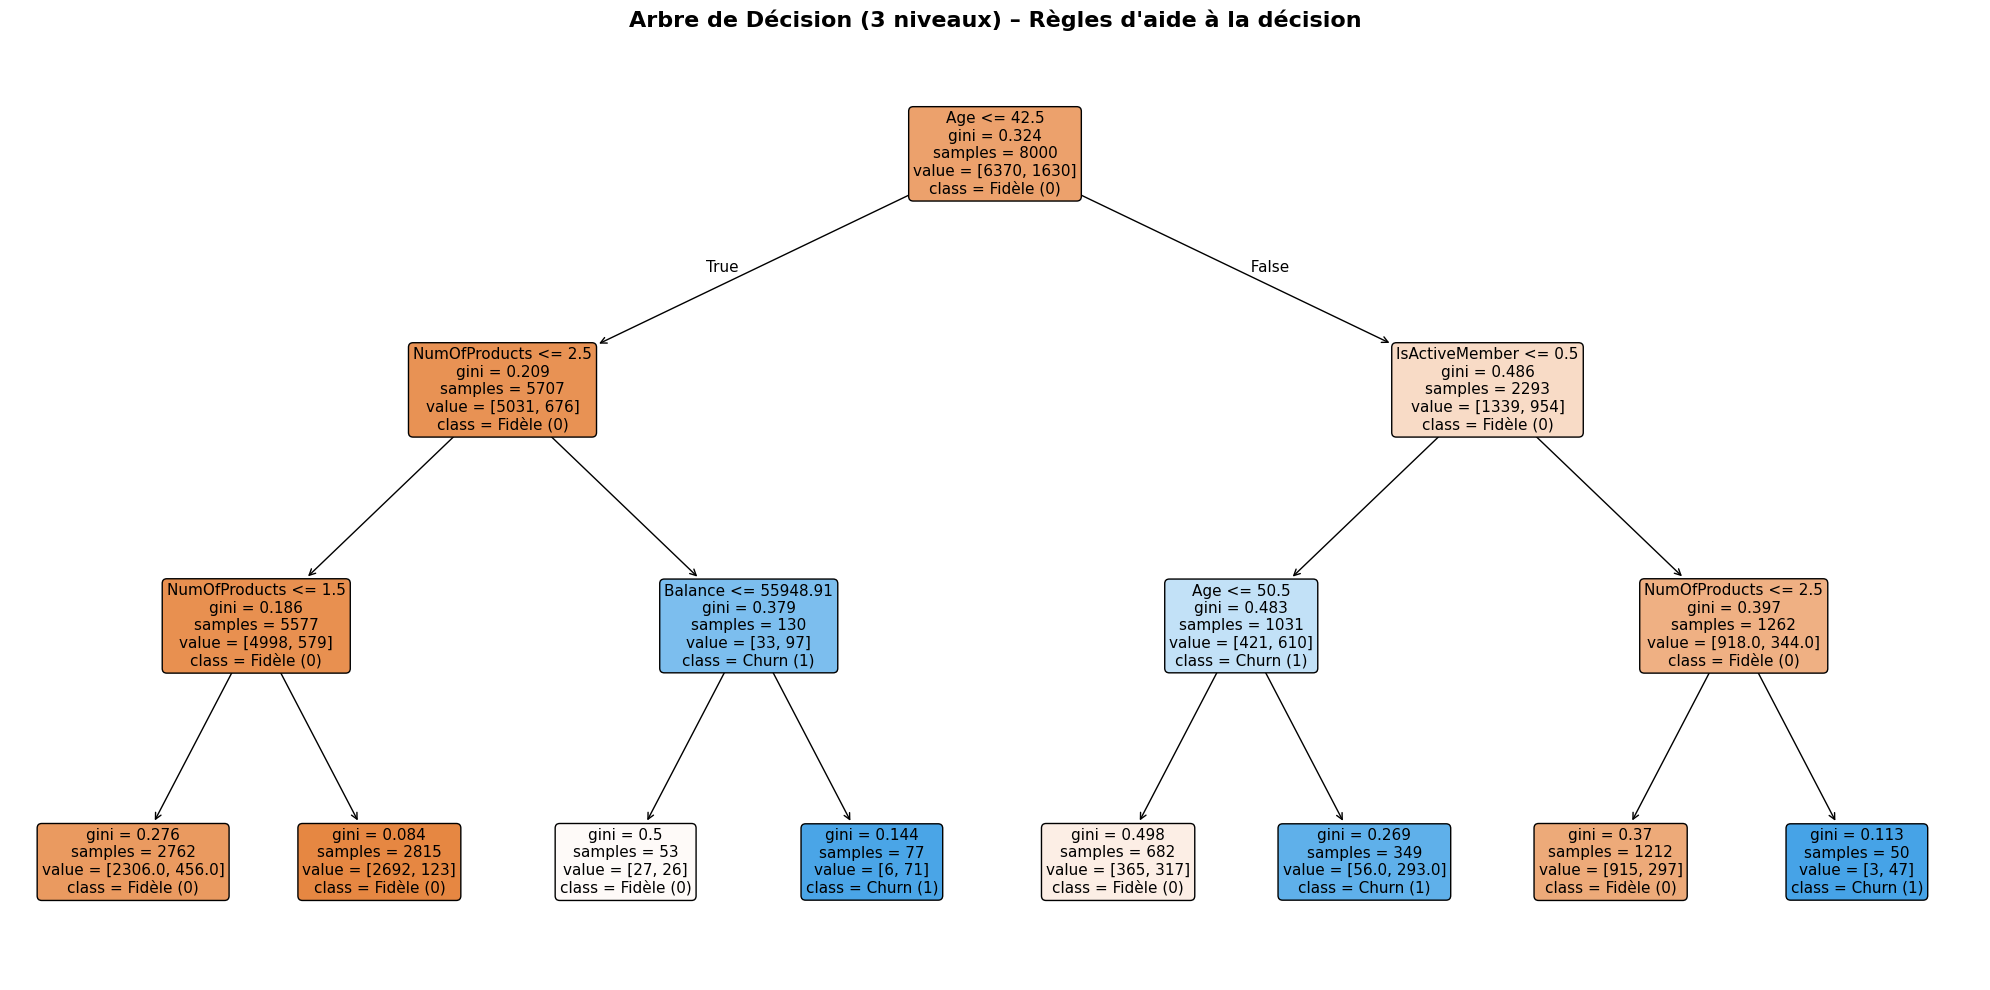

In [18]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Entraînement d'un Arbre de Décision limité à 3 niveaux (pour la lisibilité métier)
model_dt = DecisionTreeClassifier(max_depth=3, random_state=42)
model_dt.fit(X_train_nc, y_train)

# 2. Prédictions et évaluation
y_pred_dt = model_dt.predict(X_test_nc)
y_proba_dt = model_dt.predict_proba(X_test_nc)[:, 1]

print("=== RAPPORT DE CLASSIFICATION (Arbre de Décision - max_depth=3) ===")
print(classification_report(y_test, y_pred_dt))
print(f"Score ROC-AUC : {roc_auc_score(y_test, y_proba_dt):.4f}")

# 3. Visualisation graphique de l'arbre (Aide à la décision)
plt.figure(figsize=(20, 10))
plot_tree(
    model_dt,
    feature_names=X_train_nc.columns,
    class_names=['Fidèle (0)', 'Churn (1)'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Arbre de Décision (3 niveaux) – Règles d'aide à la décision", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# **Forêt Aléatoire (Random Forest)**

In [19]:
from sklearn.ensemble import RandomForestClassifier

# 1. Initialisation de la Random Forest
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train_nc, y_train) # Pas besoin du scaling pour les arbres !

# 2. Prédictions
y_pred_rf = model_rf.predict(X_test_nc)
y_proba_rf = model_rf.predict_proba(X_test_nc)[:, 1]

# 3. Évaluation des performances
print("=== RAPPORT DE CLASSIFICATION (Random Forest) ===")
print(classification_report(y_test, y_pred_rf))
print(f"Score ROC-AUC : {roc_auc_score(y_test, y_proba_rf):.4f}")

=== RAPPORT DE CLASSIFICATION (Random Forest) ===
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1592
           1       0.80      0.48      0.60       408

    accuracy                           0.87      2000
   macro avg       0.84      0.72      0.76      2000
weighted avg       0.86      0.87      0.85      2000

Score ROC-AUC : 0.8649


# **XGBoost**

In [20]:
from xgboost import XGBClassifier

# 1. Initialisation et entraînement du modèle XGBoost
model_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)
model_xgb.fit(X_train_nc, y_train)

# 2. Prédictions
y_pred_xgb = model_xgb.predict(X_test_nc)
y_proba_xgb = model_xgb.predict_proba(X_test_nc)[:, 1]

# 3. Évaluation des performances
print("=== RAPPORT DE CLASSIFICATION (XGBoost) ===")
print(classification_report(y_test, y_pred_xgb))
print(f"Score ROC-AUC : {roc_auc_score(y_test, y_proba_xgb):.4f}")

=== RAPPORT DE CLASSIFICATION (XGBoost) ===
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1592
           1       0.77      0.50      0.61       408

    accuracy                           0.87      2000
   macro avg       0.82      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000

Score ROC-AUC : 0.8779


# **Validation croisée**

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

# 1. Configuration de la validation croisée stratifiée (5 plis)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Définition des modèles à comparer
modeles = {
    "Régression Logistique": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),
    "Arbre de Décision (depth=3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='logloss')
}

# 3. Exécution de la validation croisée et sauvegarde des métriques
resultats_cv = []

for nom, modele in modeles.items():
    scores = cross_validate(
        modele,
        X_no_complain,
        y,
        cv=skf,
        scoring=['roc_auc', 'recall', 'f1'],
        n_jobs=-1
    )

    resultats_cv.append({
        "Modèle": nom,
        "ROC-AUC (CV)": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        "Rappel (CV)": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        "F1-Score (CV)": f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        "_auc_tri": scores['test_roc_auc'].mean()
    })

print("Validation croisée stratifiée (k=5) terminée avec succès !")

Validation croisée stratifiée (k=5) terminée avec succès !


# **Tableau comparatif des 4 modèles**

In [22]:
# Création et affichage du tableau comparatif officiel (Validation Croisée k=5)
df_comparaison_cv = (
    pd.DataFrame(resultats_cv)
    .sort_values(by="_auc_tri", ascending=False)
    .drop(columns=["_auc_tri"])
    .reset_index(drop=True)
)

display(df_comparaison_cv)

,Modèle,ROC-AUC (CV),Rappel (CV),F1-Score (CV)
0,XGBoost,0.8633 ± 0.0081,0.4843 ± 0.0116,0.5935 ± 0.0076
1,Random Forest,0.8517 ± 0.0092,0.4509 ± 0.0181,0.5712 ± 0.0174
2,Arbre de Décision (depth=3),0.7955 ± 0.0094,0.2826 ± 0.0380,0.4168 ± 0.0405
3,Régression Logistique,0.7644 ± 0.0060,0.2149 ± 0.0171,0.3157 ± 0.0203


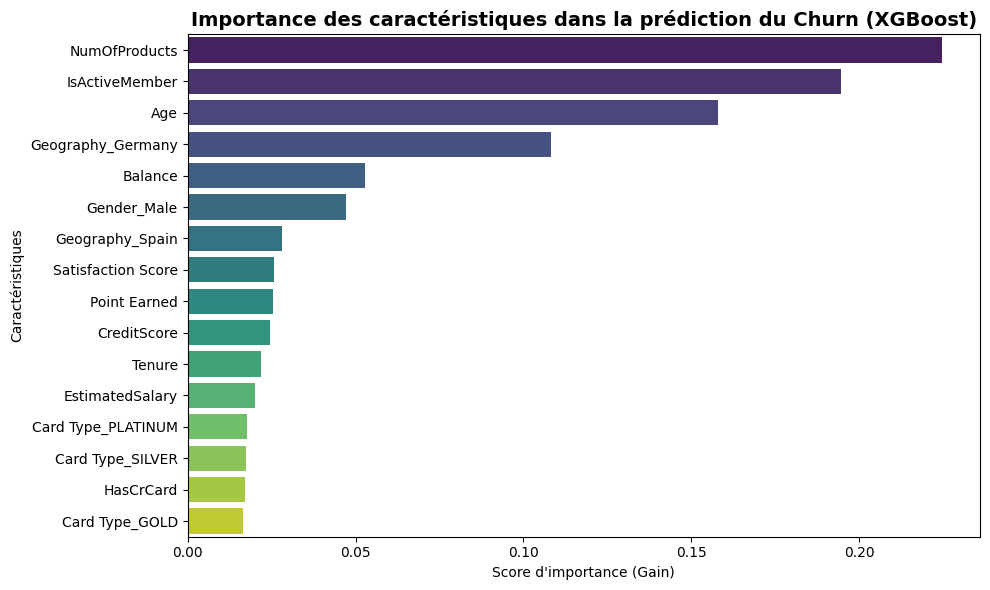

In [23]:
# 1. Création du DataFrame d'importance des caractéristiques
importance_df = pd.DataFrame({
    'Feature': X_train_nc.columns,
    'Importance': model_xgb.feature_importances_
}).sort_values(by='Importance', ascending=False)

# 2. Affichage du graphique sans avertissement Seaborn
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df,
    hue='Feature',
    legend=False,
    palette='viridis'
)
plt.title("Importance des caractéristiques dans la prédiction du Churn (XGBoost)", fontsize=14, fontweight='bold')
plt.xlabel("Score d'importance (Gain)")
plt.ylabel("Caractéristiques")
plt.tight_layout()
plt.show()

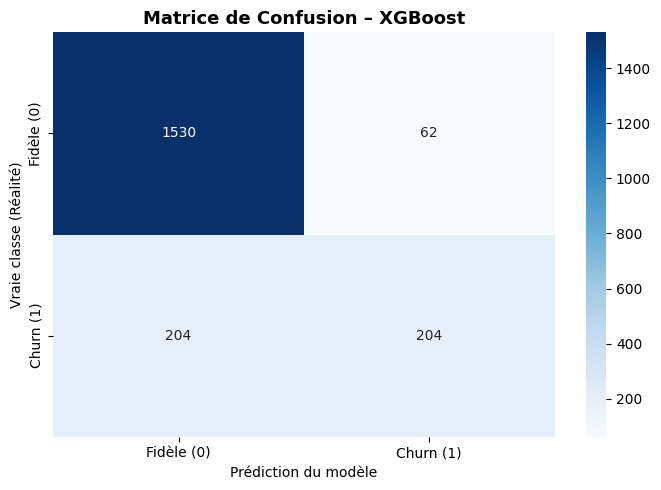

In [24]:
# 1. Génération de la matrice de confusion
cm = confusion_matrix(y_test, y_pred_xgb)

# 2. Affichage visuel avec Seaborn
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fidèle (0)', 'Churn (1)'],
            yticklabels=['Fidèle (0)', 'Churn (1)'])

plt.title("Matrice de Confusion – XGBoost", fontsize=13, fontweight='bold')
plt.xlabel("Prédiction du modèle")
plt.ylabel("Vraie classe (Réalité)")
plt.tight_layout()
plt.show()

Exportation Power BI

In [25]:
# --- EXPORT 1 : Jeu de test (2 000 clients) pour la Page 1 et la Matrice de confusion ---
df_powerbi = df.loc[y_test.index].copy()
df_powerbi['Proba_Churn_XGBoost'] = y_proba_xgb
df_powerbi['Prediction_Churn_XGBoost'] = y_pred_xgb
df_powerbi.to_csv('bank_churn_predictions_powerbi.csv', index=False)

# --- EXPORT 2 : Importance des variables (XGBoost) pour la Page 2 ---
importance_df.to_csv('importance_xgboost.csv', index=False)

# --- EXPORT 3 : Comparaison numérique des 4 modèles (CV k=5) pour la Page 2 ---
df_modeles_pbi = pd.DataFrame([
    {
        'Modele': r['Modèle'],
        'ROC_AUC_Moyenne': float(r['ROC-AUC (CV)'].split(' ± ')[0]),
        'ROC_AUC_EcartType': float(r['ROC-AUC (CV)'].split(' ± ')[1]),
        'Rappel_Moyenne': float(r['Rappel (CV)'].split(' ± ')[0]),
        'Rappel_EcartType': float(r['Rappel (CV)'].split(' ± ')[1]),
        'F1_Moyenne': float(r['F1-Score (CV)'].split(' ± ')[0]),
        'F1_EcartType': float(r['F1-Score (CV)'].split(' ± ')[1])
    }
    for r in resultats_cv
]).sort_values(by='ROC_AUC_Moyenne', ascending=False).reset_index(drop=True)

df_modeles_pbi.to_csv('comparaison_modeles_powerbi.csv', index=False)

print("Les 3 fichiers CSV pour Power BI ont été générés avec succès :")
print(f"1. bank_churn_predictions_powerbi.csv ({len(df_powerbi)} lignes)")
print(f"2. importance_xgboost.csv ({len(importance_df)} variables)")
print(f"3. comparaison_modeles_powerbi.csv ({len(df_modeles_pbi)} modèles triés par ROC-AUC)")
display(df_modeles_pbi)

Les 3 fichiers CSV pour Power BI ont été générés avec succès :
1. bank_churn_predictions_powerbi.csv (2000 lignes)
2. importance_xgboost.csv (16 variables)
3. comparaison_modeles_powerbi.csv (4 modèles triés par ROC-AUC)


,Modele,ROC_AUC_Moyenne,ROC_AUC_EcartType,Rappel_Moyenne,Rappel_EcartType,F1_Moyenne,F1_EcartType
0,XGBoost,0.86,0.01,0.48,0.01,0.59,0.01
1,Random Forest,0.85,0.01,0.45,0.02,0.57,0.02
2,Arbre de Décision (depth=3),0.80,0.01,0.28,0.04,0.42,0.04
3,Régression Logistique,0.76,0.01,0.21,0.02,0.32,0.02
